In [1]:
# Cell 1: Load the cleaned dataset from Milestone 1
from google.colab import drive
drive.mount('/content/drive')

import os
import ast
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = "/content/drive/MyDrive/TED_Talk_Recommendation"
DATA_PATH = os.path.join(BASE_DIR, "ted_talks_cleaned.csv")
MODEL_DIR = os.path.join(BASE_DIR, "model_artifacts")

os.makedirs(MODEL_DIR, exist_ok=True)

clean_df = pd.read_csv(DATA_PATH)

required_columns = ["title", "topics", "description", "transcript"]
missing_columns = [
    col for col in required_columns if col not in clean_df.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print("Cleaned dataset shape:", clean_df.shape)
print("Model artifacts folder:", MODEL_DIR)
display(clean_df.head(3))

Mounted at /content/drive
Cleaned dataset shape: (4005, 23)
Model artifacts folder: /content/drive/MyDrive/TED_Talk_Recommendation/model_artifacts


,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,...,duration,topics,related_talks,url,description,transcript,topic_count,published_year,topics_text,combined_text
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523392,2006-02-25,2006-06-27,TED2006,...,977,"['alternative energy', 'cars', 'climate change...","{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre...",9,2006,alternative energy cars climate change culture...,Averting the climate crisis alternative energy...
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501685,2006-02-22,2006-06-27,TED2006,...,1190,"['Africa', 'Asia', 'Google', 'demo', 'economic...","{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac...",11,2006,Africa Asia Google demo economics global issue...,The best stats you've ever seen Africa Asia Go...
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920832,2006-02-24,2006-06-27,TED2006,...,1286,"['computers', 'entertainment', 'interface desi...","{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun...",9,2006,computers entertainment interface design media...,Simplicity sells computers entertainment inter...


In [2]:
# Cell 2: Prepare text features for recommendation
def parse_topics(value):
    if isinstance(value, list):
        items = value
    elif pd.isna(value):
        items = []
    else:
        try:
            parsed = ast.literal_eval(str(value))
            items = parsed if isinstance(parsed, list) else str(value).split(",")
        except (ValueError, SyntaxError):
            items = str(value).split(",")

    return [
        str(item).strip().lower()
        for item in items
        if str(item).strip()
    ]

clean_df["title"] = clean_df["title"].fillna("").astype(str).str.strip()
clean_df = clean_df[clean_df["title"] != ""].copy()

clean_df["topics_list"] = clean_df["topics"].apply(parse_topics)
clean_df["topics_text"] = clean_df["topics_list"].apply(
    lambda items: " ".join(items)
)

for col in ["description", "transcript"]:
    clean_df[col] = clean_df[col].fillna("").astype(str)

text_columns = ["title", "topics_text", "description", "transcript"]

for col in text_columns:
    clean_df[col] = (
        clean_df[col]
        .str.lower()
        .str.replace(r"<[^>]+>", " ", regex=True)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

clean_df["combined_text"] = clean_df[text_columns].agg(" ".join, axis=1)
clean_df = clean_df.reset_index(drop=True)

print("Talks available:", len(clean_df))
print("Empty combined text:",
      (clean_df["combined_text"].str.strip() == "").sum())

Talks available: 4005
Empty combined text: 0


In [3]:
# Cell 3: Convert the talk text into TF-IDF vectors
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2
)

tfidf_matrix = tfidf.fit_transform(clean_df["combined_text"])

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))
print("Stop words:", tfidf.get_params()["stop_words"])
print("N-gram range:", tfidf.get_params()["ngram_range"])
print("Minimum document frequency:", tfidf.get_params()["min_df"])

TF-IDF matrix shape: (4005, 50000)
Vocabulary size: 50000
Stop words: english
N-gram range: (1, 2)
Minimum document frequency: 2


In [4]:
# Cell 4: Calculate Cosine Similarity and Recommend Similar TED Talks
from sklearn.metrics.pairwise import cosine_similarity

def recommend_talks(talk_title, top_n=5):
    matches = clean_df.index[
        clean_df["title"].str.casefold()
        == talk_title.strip().casefold()
    ].tolist()

    if not matches:
        print("Talk title not found. Please enter an exact title.")
        return None

    talk_idx = matches[0]

    scores = cosine_similarity(
        tfidf_matrix[talk_idx],
        tfidf_matrix
    ).ravel()

    # Exclude the input talk itself
    scores[talk_idx] = -1

    top_indices = np.argsort(scores)[::-1][:top_n]

    output_columns = [
        col for col in ["title", "speaker_1", "topics", "url"]
        if col in clean_df.columns
    ]

    results = clean_df.iloc[top_indices][output_columns].copy()
    results["similarity_score"] = scores[top_indices]

    return results.reset_index(drop=True)

display(recommend_talks("Do schools kill creativity?", top_n=5))

,title,speaker_1,topics,url,similarity_score
0,bring on the learning revolution!,Sir Ken Robinson,"['children', 'creativity', 'education', 'inven...",https://www.ted.com/talks/sir_ken_robinson_bri...,0.301597
1,how to escape education's death valley,Sir Ken Robinson,"['culture', 'education', 'teaching', 'student']",https://www.ted.com/talks/sir_ken_robinson_how...,0.291415
2,nerdcore comedy,Ze Frank,"['collaboration', 'comedy', 'community', 'cult...",https://www.ted.com/talks/ze_frank_nerdcore_co...,0.236661
3,a one-man world summit,Rory Bremner,"['comedy', 'global issues', 'government', 'per...",https://www.ted.com/talks/rory_bremner_a_one_m...,0.228985
4,how to run a company with (almost) no rules,Ricardo Semler,"['business', 'creativity', 'philosophy', 'work...",https://www.ted.com/talks/ricardo_semler_how_t...,0.222859


In [5]:
# Cell 5: Test recommendations for different talks
test_titles = [
    "Do schools kill creativity?",
    "The best stats you've ever seen"
]

test_results = []

for title in test_titles:
    print("\nInput talk:", title)
    results = recommend_talks(title, top_n=5)

    if results is not None:
        display(results[["title", "similarity_score"]])

        results = results.copy()
        results.insert(0, "input_talk", title)
        test_results.append(results)

if test_results:
    sample_recommendations = pd.concat(test_results, ignore_index=True)
    sample_recommendations.to_csv(
        os.path.join(MODEL_DIR, "sample_recommendations.csv"),
        index=False
    )
    print("Sample recommendations saved.")


Input talk: Do schools kill creativity?


,title,similarity_score
0,bring on the learning revolution!,0.301597
1,how to escape education's death valley,0.291415
2,nerdcore comedy,0.236661
3,a one-man world summit,0.228985
4,how to run a company with (almost) no rules,0.222859



Input talk: The best stats you've ever seen


,title,similarity_score
0,let my dataset change your mindset,0.511805
1,new insights on poverty,0.360768
2,the good news of the decade? we're winning the...,0.316988
3,"global population growth, box by box",0.288569
4,"insights on hiv, in stunning data visuals",0.278242


Sample recommendations saved.


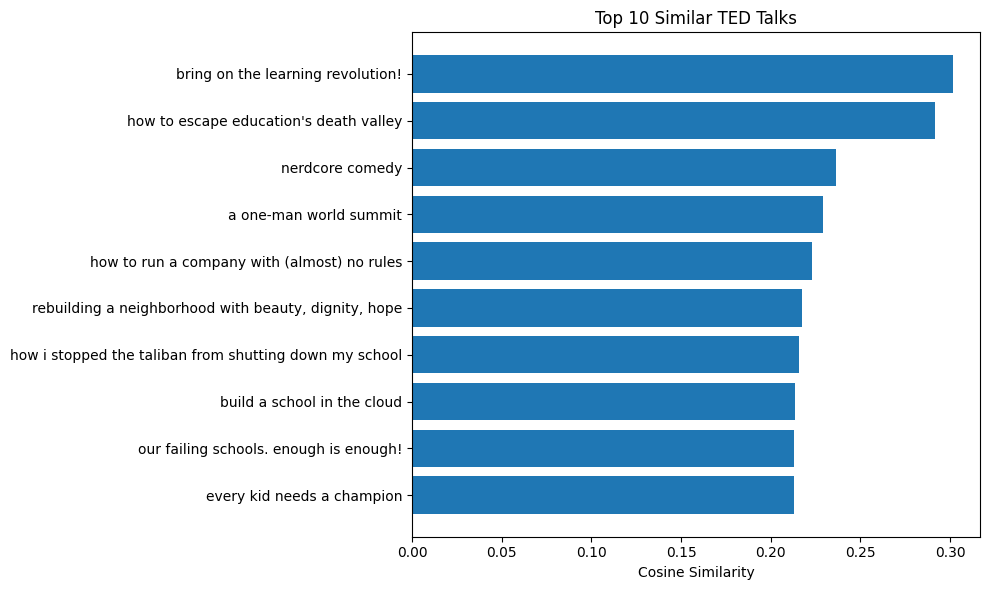

Plot saved to: /content/drive/MyDrive/TED_Talk_Recommendation/model_artifacts/similarity_scores.png


In [6]:
# Cell 6: Visualize the top 10 recommendation scores
sample = recommend_talks("Do schools kill creativity?", top_n=10)

if sample is not None:
    plot_data = sample.sort_values("similarity_score")

    plt.figure(figsize=(10, 6))
    plt.barh(plot_data["title"], plot_data["similarity_score"])
    plt.xlabel("Cosine Similarity")
    plt.title("Top 10 Similar TED Talks")
    plt.tight_layout()

    plot_path = os.path.join(MODEL_DIR, "similarity_scores.png")
    plt.savefig(plot_path, dpi=200, bbox_inches="tight")
    plt.show()

    print("Plot saved to:", plot_path)

In [7]:
# Cell 7: Evaluate recommendations using topic overlap
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer

train_df, test_df = train_test_split(
    clean_df,
    test_size=0.2,
    random_state=42
)

eval_vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2
)

train_matrix = eval_vectorizer.fit_transform(train_df["combined_text"])
test_matrix = eval_vectorizer.transform(test_df["combined_text"])

train_topic_sets = train_df["topics_list"].apply(set).tolist()
test_topic_sets = test_df["topics_list"].apply(set).tolist()

K = 5
precision_scores = []
recall_scores = []
ndcg_scores = []
map_scores = []

for i, query_topics in enumerate(test_topic_sets):
    if not query_topics:
        continue

    relevant = np.array([
        bool(query_topics.intersection(candidate_topics))
        for candidate_topics in train_topic_sets
    ])

    # Skip queries without any relevant training talks
    if not relevant.any():
        continue

    scores = cosine_similarity(
        test_matrix[i],
        train_matrix
    ).ravel()

    top_indices = np.argsort(scores)[::-1][:K]
    hits = relevant[top_indices].astype(int)

    precision_scores.append(hits.sum() / K)
    recall_scores.append(hits.sum() / relevant.sum())

    discounts = 1 / np.log2(np.arange(2, K + 2))
    dcg = np.sum(hits * discounts)

    ideal_hits = np.sort(relevant.astype(int))[::-1][:K]
    idcg = np.sum(ideal_hits * discounts)
    ndcg_scores.append(dcg / idcg if idcg > 0 else 0)

    precision_at_rank = np.cumsum(hits) / np.arange(1, K + 1)
    average_precision = (
        np.sum(precision_at_rank * hits)
        / min(relevant.sum(), K)
    )
    map_scores.append(average_precision)

if precision_scores:
    evaluation_results = pd.DataFrame({
        "Metric": ["Precision@5", "Recall@5", "NDCG@5", "MAP@5"],
        "Score": [
            np.mean(precision_scores),
            np.mean(recall_scores),
            np.mean(ndcg_scores),
            np.mean(map_scores)
        ]
    })

    display(evaluation_results)

    print("Eligible test talks:", len(precision_scores))

    evaluation_results.to_csv(
        os.path.join(MODEL_DIR, "evaluation_results.csv"),
        index=False
    )
else:
    evaluation_results = pd.DataFrame()
    print("No eligible test talks found. Check the topics data.")

,Metric,Score
0,Precision@5,0.851685
1,Recall@5,0.004529
2,NDCG@5,0.856256
3,MAP@5,0.804432


Eligible test talks: 801


In [8]:
# Cell 8: Save artifacts for reuse and deployment
import joblib
from scipy.sparse import save_npz

joblib.dump(
    tfidf,
    os.path.join(MODEL_DIR, "tfidf_vectorizer.joblib")
)

save_npz(
    os.path.join(MODEL_DIR, "tfidf_matrix.npz"),
    tfidf_matrix
)

metadata_columns = [
    col for col in ["title", "speaker_1", "topics", "url", "description"]
    if col in clean_df.columns
]

clean_df[metadata_columns].to_csv(
    os.path.join(MODEL_DIR, "talk_metadata.csv"),
    index=False
)

# Save the parameters used to build the main model
model_info = {
    "recommendation_method": "Content-based filtering",
    "vectorization": "TF-IDF",
    "similarity": "Cosine similarity",
    "max_features": 50000,
    "ngram_range": [1, 2],
    "min_df": 2,
    "stop_words": "english",
    "number_of_talks": int(len(clean_df)),
    "number_of_features": int(tfidf_matrix.shape[1])
}

import json

with open(os.path.join(MODEL_DIR, "model_config.json"), "w") as f:
    json.dump(model_info, f, indent=4)

print("Model artifacts saved successfully.")
print("\nSaved files:")

for filename in sorted(os.listdir(MODEL_DIR)):
    print("-", filename)

Model artifacts saved successfully.

Saved files:
- evaluation_results.csv
- model_comparison.csv
- model_config.json
- sample_recommendations.csv
- similarity_scores.png
- talk_metadata.csv
- tfidf_matrix.npz
- tfidf_vectorizer.joblib


In [9]:
# Cell 9: Validate recommendation output

input_title = "Do schools kill creativity?"
results = recommend_talks(input_title, top_n=5)

if results is not None:
    assert len(results) == 5, "Expected 5 recommendations"
    assert results["title"].nunique() == 5, "Duplicate recommendations found"
    assert not (
        results["title"].str.casefold()
        == input_title.casefold()
    ).any(), "The input talk was recommended to itself"

    print("Recommendation validation passed.")
    display(results[["title", "similarity_score"]])

Recommendation validation passed.


,title,similarity_score
0,bring on the learning revolution!,0.301597
1,how to escape education's death valley,0.291415
2,nerdcore comedy,0.236661
3,a one-man world summit,0.228985
4,how to run a company with (almost) no rules,0.222859


# Milestone 2: Feature Engineering and Recommendation Engine

## 1. Feature Engineering and Vectorization

The TED Talks dataset was preprocessed using the title, topics, description, and transcript fields. These fields were combined to represent each talk. Missing textual values were replaced with empty strings, and the text was normalized to lowercase with whitespace cleaned.

TF-IDF vectorization was applied with English stop-word removal, a maximum vocabulary of 50,000 features, unigrams and bigrams, and a minimum document frequency of two.

## 2. Recommendation Engine

A content-based recommendation system was implemented using cosine similarity between TF-IDF vectors. Given a TED Talk title, the system ranks other talks by textual similarity and returns the top recommendations.

## 3. Model Artifacts

The fitted TF-IDF vectorizer, sparse feature matrix, talk metadata, model configuration, sample recommendations, similarity visualization, and offline evaluation results are saved in Google Drive for reuse.

## 4. Evaluation

An 80/20 train/test split was used for an initial offline evaluation. Precision@5, Recall@5, NDCG@5, and MAP@5 were calculated using shared topic tags as a proxy for relevance.

## 5. Limitations

The dataset used for this implementation does not provide user interaction data for collaborative filtering. The evaluation based on topic overlap is an approximation and does not directly measure user satisfaction. Future improvements may include user feedback, manually judged relevance, or embedding-based recommendations.

In [10]:
# Cell 10: Verify saved artifacts
required_files = [
    "tfidf_vectorizer.joblib",
    "tfidf_matrix.npz",
    "talk_metadata.csv",
    "model_config.json"
]

for filename in required_files:
    path = os.path.join(MODEL_DIR, filename)
    print(filename, "->", "OK" if os.path.exists(path) else "MISSING")

print("\nFinal dataset rows:", len(clean_df))
print("Final TF-IDF matrix shape:", tfidf_matrix.shape)

tfidf_vectorizer.joblib -> OK
tfidf_matrix.npz -> OK
talk_metadata.csv -> OK
model_config.json -> OK

Final dataset rows: 4005
Final TF-IDF matrix shape: (4005, 50000)


In [11]:
# Check how many topic-relevant talks are retrieved
relevant_counts = []
retrieved_relevant_counts = []

for i, query_topics in enumerate(test_topic_sets):
    if not query_topics:
        continue

    relevant = np.array([
        bool(query_topics.intersection(candidate_topics))
        for candidate_topics in train_topic_sets
    ])

    if not relevant.any():
        continue

    scores = cosine_similarity(test_matrix[i], train_matrix).ravel()
    top_indices = np.argsort(scores)[::-1][:5]

    relevant_counts.append(int(relevant.sum()))
    retrieved_relevant_counts.append(int(relevant[top_indices].sum()))

print("Eligible queries:", len(relevant_counts))
print("Average relevant training talks per query:", np.mean(relevant_counts))
print("Average relevant talks found in top 5:",
      np.mean(retrieved_relevant_counts))

Eligible queries: 801
Average relevant training talks per query: 1125.489388264669
Average relevant talks found in top 5: 4.258426966292135
